# Court model: a walkthrough of every experiment

NBA 2025-26 player tracking (666 games, 19.4M frames) → shot models → space ("holes") → rebounding →
player ratings → lineup models → self-supervised world models.

**The question throughout:** can tracking data rate players better than the public metrics (RAPM, DARKO, EPM, LEBRON),
and can a lineup model *learn* fit and usage instead of having them imposed?

**How everything is judged:** the same honest out-of-sample test wherever possible:

* **Shot level:** train on games before 2026-04-01, test on the 186 games after.
* **Game level (ratings):** a *rolling-origin* test. Six blocks from March to June 2026; for each block, fit only on
  games before it, predict the winner of every game in it from the lineups that actually played. That's 423 test games.
  Scored by AUC and log loss, with paired game-bootstrap 95% intervals.

Every chart below is drawn from the saved result files of those runs.

In [1]:
import json, pickle, csv, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
R, PC = ROOT / 'results', ROOT / 'results/_pc'
sys.path.insert(0, str(ROOT))
J = lambda p: json.load(open(p))

mpl.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.alpha': 0.25, 'axes.titleweight': 'bold', 'axes.titlesize': 12, 'font.size': 10,
                     'axes.titlelocation': 'left'})
C = dict(base='#9aa3ad', ours='#2f6fde', good='#1f9d6b', bad='#d1495b', warn='#e59f24', ink='#2b2f36', alt='#7b5ea7')

def auc(y, p):
    # rank AUC (Mann-Whitney), no sklearn
    y = np.asarray(y).astype(bool); r = np.argsort(np.argsort(p)) + 1.0
    n1 = y.sum(); n0 = (~y).sum()
    return (r[y].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

def ci_bars(ax, labels, mid, lo, hi, colors, xlabel, zero=True):
    y = np.arange(len(labels))[::-1]
    ax.barh(y, mid, color=colors, alpha=0.9, height=0.62)
    ax.errorbar(mid, y, xerr=[np.array(mid) - np.array(lo), np.array(hi) - np.array(mid)], fmt='none', ecolor=C['ink'], capsize=3, lw=1)
    ax.set_yticks(y, labels); ax.set_xlabel(xlabel)
    if zero: ax.axvline(0, color=C['ink'], lw=0.8)

names = {}
for r in csv.DictReader(open(R / 'rapm/players.csv')):
    names[int(r['player_id'])] = r['name']
print('ready')

ready


## 1. The data, and why gaps matter

The tracking archive has 19.4M frames, but only about **31% of frames have all ten players identified**. Most gaps are short.
91% of missing-player episodes last 1 s or less, but the long ones carry a large share of the missing time.

**Why it matters:** anything geometric (spacing, openness, who controls space) needs all ten players. So later
models interpolate gaps of up to 1 s and *inflate the positional uncertainty* in proportion to how far each point is
from a real sample, rather than pretending interpolated points are exact.

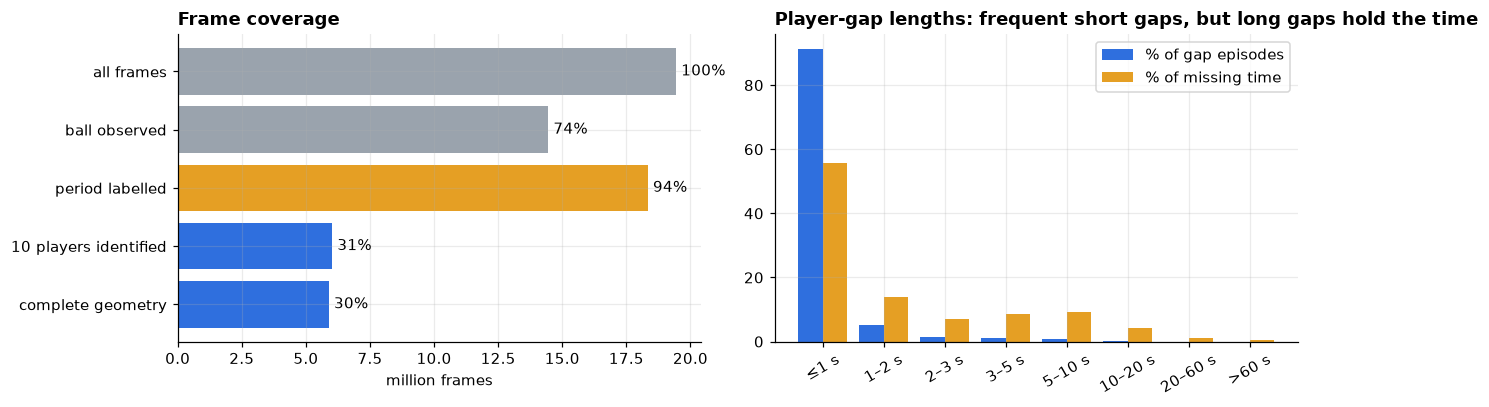

In [2]:
s = J(R / 'summary.json')['counts']; g = J(R / 'gap_statistics.json')['players']
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
lab = ['all frames', 'ball observed', 'period labelled', '10 players identified', 'complete geometry']
val = [s['frames'], s['ball_observed_frames'], s['labeled_period_frames'], s['ten_identified_players_frames'], s['complete_geometry_frames']]
ax[0].barh(lab[::-1], np.array(val[::-1]) / 1e6, color=[C['ours']] * 2 + [C['warn']] + [C['base']] * 2)
for i, v in enumerate(val[::-1]):
    ax[0].text(v / 1e6 + 0.2, i, f'{v / s["frames"]:.0%}', va='center')
ax[0].set_xlabel('million frames'); ax[0].set_title('Frame coverage')
x = np.arange(len(g['bins']))
ax[1].bar(x - 0.2, g['episode_percent'], 0.4, label='% of gap episodes', color=C['ours'])
ax[1].bar(x + 0.2, g['missing_time_percent'], 0.4, label='% of missing time', color=C['warn'])
ax[1].set_xticks(x, g['bins'], rotation=30); ax[1].legend(); ax[1].set_title('Player-gap lengths: frequent short gaps, but long gaps hold the time')
plt.tight_layout()

## 2. Shot-make prediction: tracking at release helps

**Baseline A** uses location, shot type and action words from the play-by-play, plus an empirical-Bayes shooter prior built only
from earlier dates. **B** adds hand-built tracking features at the moment of release:

* defender distances and angles, and closing speed
* shooter speed and direction
* spacing

**Result:** tracking lowers log loss by about 0.010, and the 95% interval is well away from zero. Almost all of the gain is on
**twos** (−0.015). Threes barely move (−0.001), because whether a three goes in depends on the shooter far more than on the
defender. Defender features carry most of the signal.

The last two bars use the **MAE embedding** (Section 9): the learned representation of the 2 s before release. It gives a
small, significant gain on top of the hand-built features on shots that have a window. It is weaker on its own, because the
encoder sees 5 Hz half-court frames, while the decisive defender distance happens at release.

shots with an MAE window: B + MAE vs B  Δll -0.0010  CI [-0.0018 -0.0001]


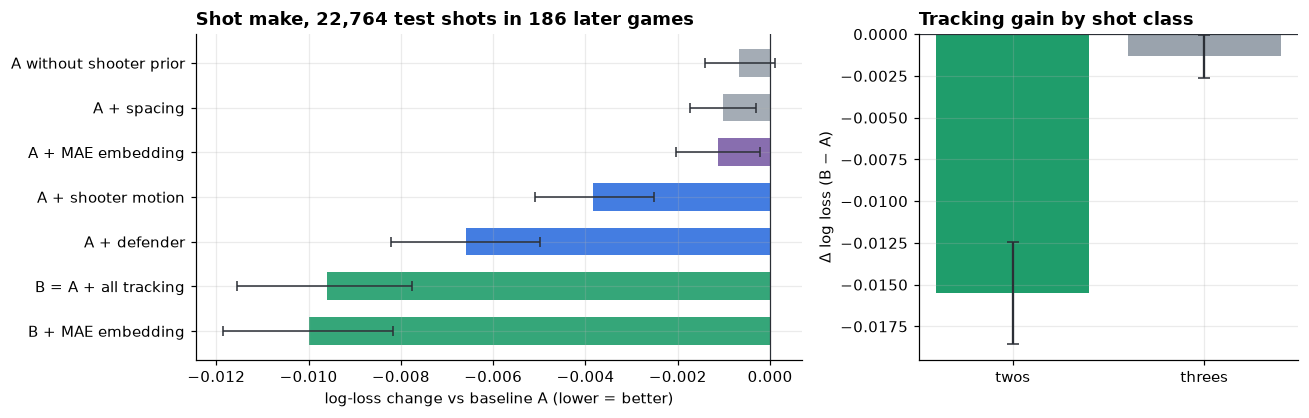

In [3]:
sm = J(R / 'shots/shot_model_mae.json')
order = ['A_minus_shooter', 'A_plus_spacing', 'A_plus_mae', 'A_plus_shooter_motion', 'A_plus_defender', 'B_plus_all_tracking', 'B_plus_mae']
pretty = {'A_minus_shooter': 'A without shooter prior', 'A_plus_spacing': 'A + spacing', 'A_plus_mae': 'A + MAE embedding',
          'A_plus_shooter_motion': 'A + shooter motion', 'A_plus_defender': 'A + defender', 'B_plus_all_tracking': 'B = A + all tracking',
          'B_plus_mae': 'B + MAE embedding'}
mid = [sm['vs_A'][k]['logloss_change'] for k in order]; lo = [sm['vs_A'][k]['ci95'][0] for k in order]; hi = [sm['vs_A'][k]['ci95'][1] for k in order]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.9), gridspec_kw=dict(width_ratios=[1.6, 1]))
ci_bars(ax[0], [pretty[k] for k in order], mid, lo, hi,
        [C['base'], C['base'], C['alt'], C['ours'], C['ours'], C['good'], C['good']], 'log-loss change vs baseline A (lower = better)')
ax[0].set_title(f"Shot make, {sm['n_test']:,} test shots in {sm['test_games']} later games")
bc = sm['by_class']
for i, k in enumerate(['two', 'three']):
    d, (l, h) = bc[k]['B_vs_A']
    ax[1].bar(i, d, color=C['good'] if k == 'two' else C['base']); ax[1].errorbar(i, d, yerr=[[d - l], [h - d]], color=C['ink'], capsize=4)
ax[1].set_xticks([0, 1], ['twos', 'threes']); ax[1].axhline(0, color=C['ink'], lw=0.8)
ax[1].set_title('Tracking gain by shot class'); ax[1].set_ylabel('Δ log loss (B − A)')
plt.tight_layout()
ww = sm['with_window']
print('shots with an MAE window: B + MAE vs B  Δll %.4f  CI %s' % (ww['B_plus_mae_vs_B_plus_all_tracking'][0], np.round(ww['B_plus_mae_vs_B_plus_all_tracking'][1], 4)))

## 3. Player ratings: from RAPM to the current best model

Each rung adds one idea, and each is tested on the same 423 rolling test games:

| arm | what it adds |
|---|---|
| `rapm` | ridge regression of stint scoring margin on who was on the floor, shrunk toward zero |
| `rapm_trk` | prior mean from **tracking descriptions** (box score plus tracking style metrics mapped to impact) |
| `hist_only` | multi-season history projection alone, no 2025-26 games |
| `rapm_hist` | RAPM shrunk toward each player's **history** instead of toward zero |
| `rapm_hist_trk` | history prior, plus tracking descriptions fit on what history leaves unexplained |
| `anchored_comp_hist_trk` | plus compressed player embeddings and a lineup graph network anchored to that backbone **(current best)** |

**Why it works:** a single half-season of stints is far too noisy for RAPM. Priors fix that. History tells you who a
player was, and tracking tells you what he does *now*, which matters most for young or changing players. Each
prior roughly halves what the next one has left to explain.

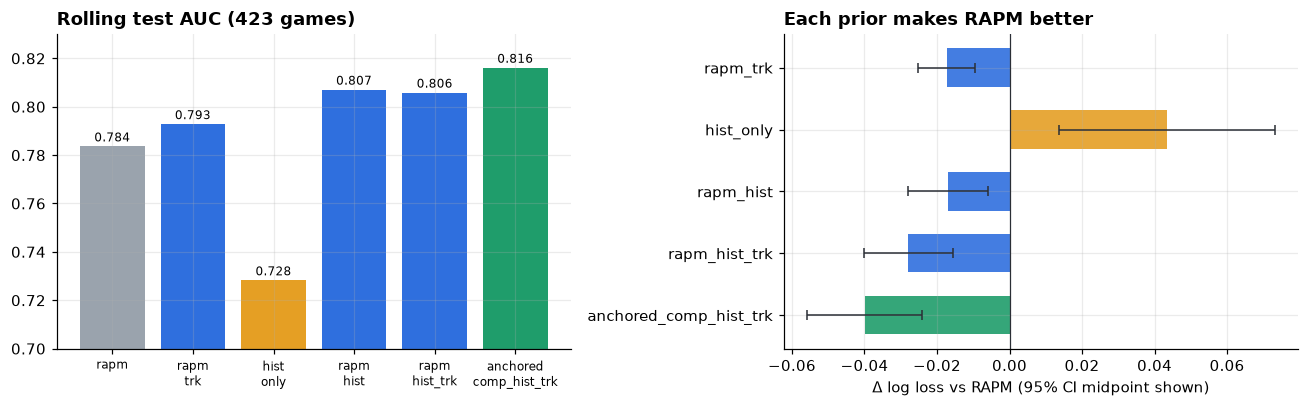

In [4]:
rp = J(PC / 'groupwar_t/rolling_prior/rolling_prior.json')['arms']
arms = ['rapm', 'rapm_trk', 'hist_only', 'rapm_hist', 'rapm_hist_trk', 'anchored_comp_hist_trk']
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
col = [C['base'], C['ours'], C['warn'], C['ours'], C['ours'], C['good']]
ax[0].bar(range(len(arms)), [rp[a]['auc'] for a in arms], color=col); ax[0].set_ylim(0.7, 0.83)
ax[0].set_xticks(range(len(arms)), [a.replace('_', '\n', 1) for a in arms], fontsize=8); ax[0].set_title('Rolling test AUC (423 games)')
for i, a in enumerate(arms): ax[0].text(i, rp[a]['auc'] + 0.002, f"{rp[a]['auc']:.3f}", ha='center', fontsize=8)
a2 = [a for a in arms if a != 'rapm']
ci_bars(ax[1], a2, [np.mean(rp[a]['d_ll_vs_rapm']) for a in a2], [rp[a]['d_ll_vs_rapm'][0] for a in a2],
        [rp[a]['d_ll_vs_rapm'][1] for a in a2], col[1:], 'Δ log loss vs RAPM (95% CI midpoint shown)')
ax[1].set_title('Each prior makes RAPM better')
plt.tight_layout()

## 4. Against the public metrics

Same 423 games, with each metric used **point in time**: only what was knowable the morning of each game.

* **DARKO:** its daily history.
* **EPM:** the *previous* season's values, since in-season snapshots aren't public.
* `epm_end_LEAKY`: EPM's **end-of-season** 2026 numbers. These have *seen the test games*, so they are an upper bound,
  not a fair competitor.

**Result:** the current best beats point-in-time DARKO on log loss, with a 95% interval of −0.053 to −0.010. It also
beats last season's EPM. It is roughly tied with end-of-season EPM, the one that has seen the answers. Averaging ours
with DARKO did not help, because DARKO adds nothing ours doesn't already have.

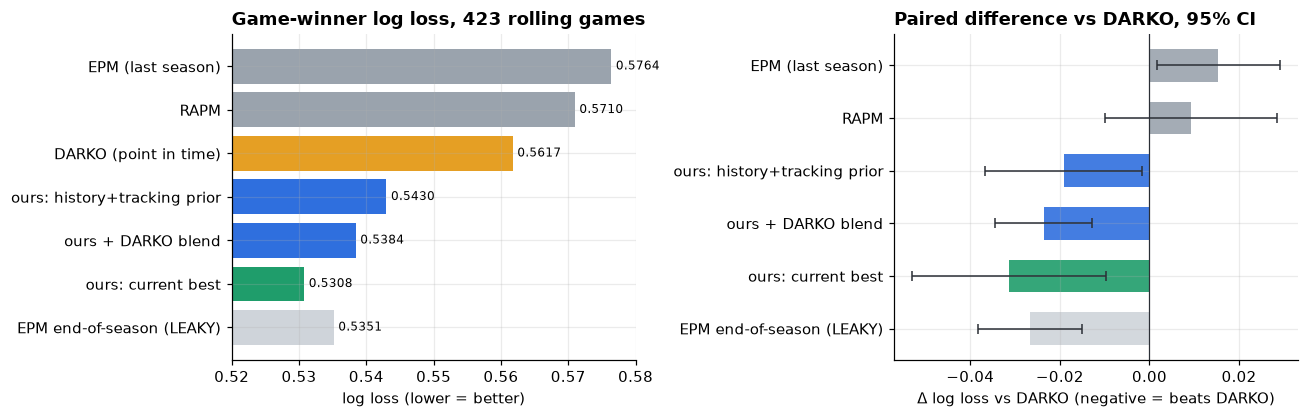

In [5]:
bm = J(PC / 'groupwar_t/benchmark/benchmark.json')['arms']
order = ['epm_prev', 'rapm', 'darko_pit', 'rapm_hist_trk', 'ours_plus_darko', 'anchored_comp_hist_trk', 'epm_end_LEAKY']
pretty = {'epm_prev': 'EPM (last season)', 'rapm': 'RAPM', 'darko_pit': 'DARKO (point in time)', 'rapm_hist_trk': 'ours: history+tracking prior',
          'ours_plus_darko': 'ours + DARKO blend', 'anchored_comp_hist_trk': 'ours: current best', 'epm_end_LEAKY': 'EPM end-of-season (LEAKY)'}
col = {'epm_prev': C['base'], 'rapm': C['base'], 'darko_pit': C['warn'], 'rapm_hist_trk': C['ours'], 'ours_plus_darko': C['ours'],
       'anchored_comp_hist_trk': C['good'], 'epm_end_LEAKY': '#cfd4da'}
fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
y = np.arange(len(order))[::-1]
ax[0].barh(y, [bm[a]['log_loss'] for a in order], color=[col[a] for a in order], hatch=None)
ax[0].set_yticks(y, [pretty[a] for a in order]); ax[0].set_xlim(0.52, 0.58); ax[0].set_xlabel('log loss (lower = better)')
for yy, a in zip(y, order): ax[0].text(bm[a]['log_loss'] + 0.0007, yy, f"{bm[a]['log_loss']:.4f}", va='center', fontsize=8)
ax[0].set_title('Game-winner log loss, 423 rolling games')
o2 = [a for a in order if a != 'darko_pit']
ci_bars(ax[1], [pretty[a] for a in o2], [np.mean(bm[a]['d_ll_vs_darko_pit']) for a in o2], [bm[a]['d_ll_vs_darko_pit'][0] for a in o2],
        [bm[a]['d_ll_vs_darko_pit'][1] for a in o2], [col[a] for a in o2], 'Δ log loss vs DARKO (negative = beats DARKO)')
ax[1].set_title('Paired difference vs DARKO, 95% CI')
plt.tight_layout()

## 5. Holes in the defense: a probabilistic control field

For every 1 ft cell of the half court:

1. Compute each player's **kinematic arrival time**: 0.2 s reaction, then acceleration up to a top speed, using his current
   velocity.
2. Treat each arrival time as Gaussian, with variance growing with distance and with that player's positional
   uncertainty (inflated for interpolated points, as in Section 1).
3. Combine each team's arrival times with **Clark's min-of-Gaussians**, giving
   C(q) = P(offense arrives first).
4. Weight by a points value map to get H = C·V. **Open space A** is the sum of H in excess of 0.5.

Removing one player at a time gives per-player credit:

* for a defender, the space he currently denies
* for an attacker, the space only he reaches first

**Why not Voronoi?** Voronoi says the nearest player owns a cell, ignoring momentum and uncertainty. In the validation below
it adds nothing over the baseline geometry, while the field adds a lot.

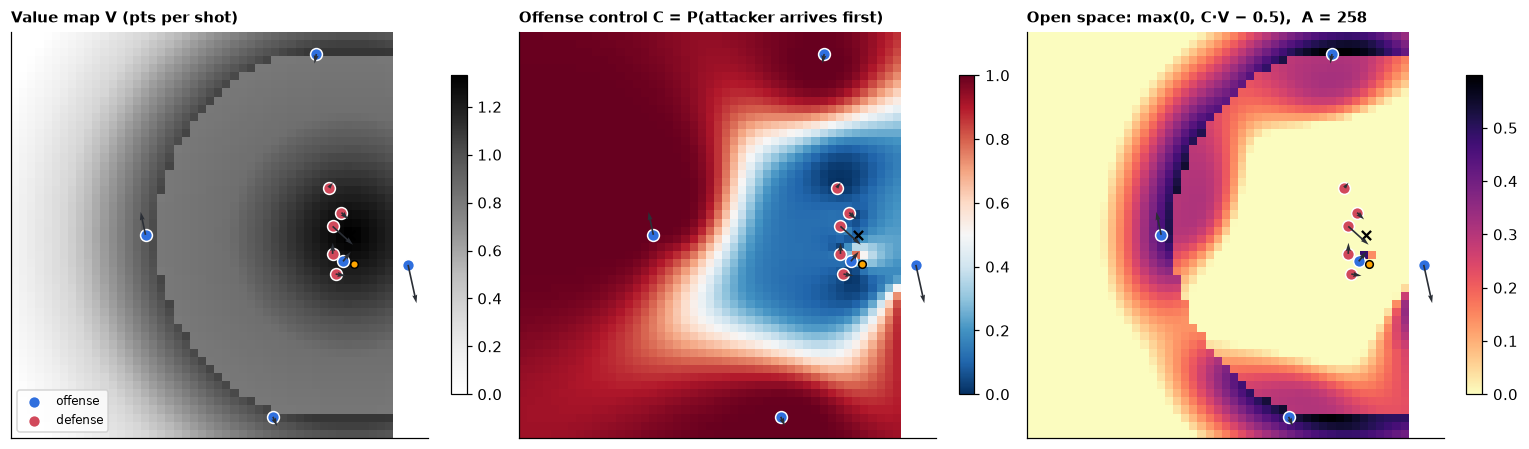

In [6]:
import torch, holes_field as hf
d = np.load(R / 'holes/0022500015.npz')
i = int(np.argsort(d['A'])[-40])  # a frame with a large open area
F = hf.Field('cpu')
pos = torch.tensor(d['pos'][i:i + 1].astype(np.float32)); vel = torch.tensor(d['vel'][i:i + 1].astype(np.float32))
mu = hf.arrival(pos, vel, F.gx, F.gy); var = hf.variance(mu, torch.tensor(d['pe'][i:i + 1].astype(np.float32)))
Cq = hf.control(mu, var)[0].numpy(); H = Cq * F.V.numpy()
nx, ny = 47, 50
fig, ax = plt.subplots(1, 3, figsize=(14, 4.4))
for a, Z, t, cm in ((ax[0], F.V.numpy(), 'Value map V (pts per shot)', 'Greys'), (ax[1], Cq, 'Offense control C = P(attacker arrives first)', 'RdBu_r'),
                    (ax[2], np.clip(H - 0.5, 0, None), f'Open space: max(0, C·V − 0.5),  A = {d["A"][i]:.0f}', 'magma_r')):
    im = a.imshow(Z.reshape(nx, ny).T, origin='lower', extent=[0, 47, -25, 25], cmap=cm, aspect='equal',
                  vmin=0 if cm != 'RdBu_r' else 0, vmax=None if cm != 'RdBu_r' else 1)
    p = d['pos'][i]; v = d['vel'][i]
    a.scatter(p[:5, 0], p[:5, 1], s=60, c=C['ours'], edgecolor='w', zorder=3, label='offense')
    a.scatter(p[5:, 0], p[5:, 1], s=60, c=C['bad'], edgecolor='w', zorder=3, label='defense')
    a.quiver(p[:, 0], p[:, 1], v[:, 0], v[:, 1], color=C['ink'], scale=120, width=0.004, zorder=3)
    a.scatter(*d['ball'][i], s=25, c='orange', edgecolor='k', zorder=4)
    a.scatter([41.75], [0], marker='x', c='k'); a.set_title(t, fontsize=10); a.grid(False); a.set_xticks([]); a.set_yticks([])
    plt.colorbar(im, ax=a, fraction=0.035)
ax[0].legend(loc='lower left', fontsize=8)
plt.tight_layout()

**Validation**, replicating section 4.2 of the paper, with tests held out by game. Does the field at time *t* predict what
the offense does next?

* a shot within 3 s
* an open shot (defender more than 6 ft away)
* a rim attempt
* the expected value of the shot

The baseline is 16 hand-built geometry features.

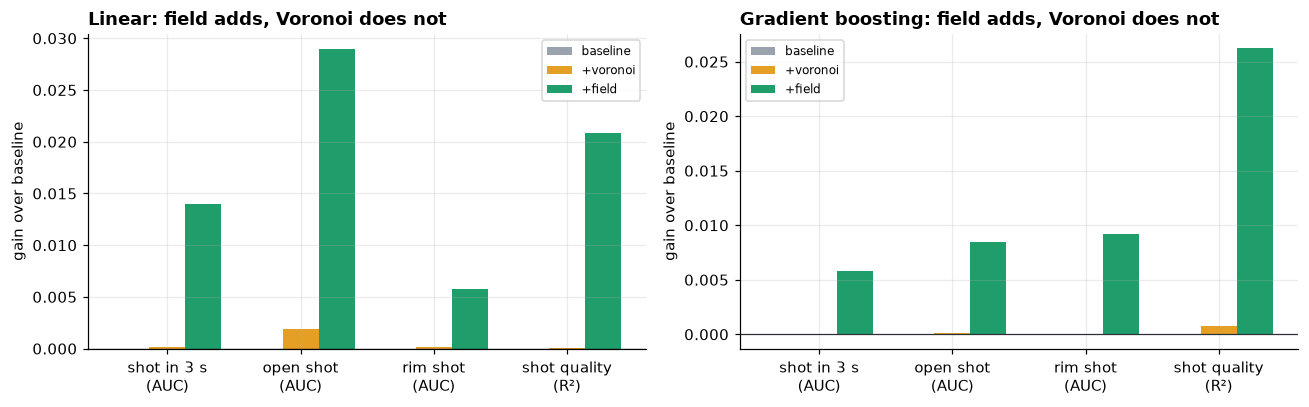

In [7]:
hv = J(R / 'holes_validate.json')
tg = ['shot', 'open_shot', 'rim_shot', 'shot_q']; tl = ['shot in 3 s\n(AUC)', 'open shot\n(AUC)', 'rim shot\n(AUC)', 'shot quality\n(R²)']
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, m in zip(ax, ['linear', 'gbm']):
    x = np.arange(4)
    for j, (arm, c) in enumerate((('baseline', C['base']), ('+voronoi', C['warn']), ('+field', C['good']))):
        vals = [hv[f'{t}|{m}|{arm}'] - (0 if t == 'shot_q' else 0) for t in tg]
        a.bar(x + (j - 1) * 0.27, [v - hv[f'{t}|{m}|baseline'] for v, t in zip(vals, tg)], 0.27, color=c, label=arm)
    a.set_xticks(x, tl); a.axhline(0, color=C['ink'], lw=0.8); a.set_ylabel('gain over baseline')
    a.set_title(f'{"Linear" if m == "linear" else "Gradient boosting"}: field adds, Voronoi does not'); a.legend(fontsize=8)
plt.tight_layout()

**Per-player holes metrics** are very stable from one half of the season to the other (split-half *r* of 0.81–0.95), but
they describe **role**, not value.

* **Openness:** stars are the *least* open players. That is gravity: defenses collapse onto them.
* **Space created per touch:** this is where the creators show up.

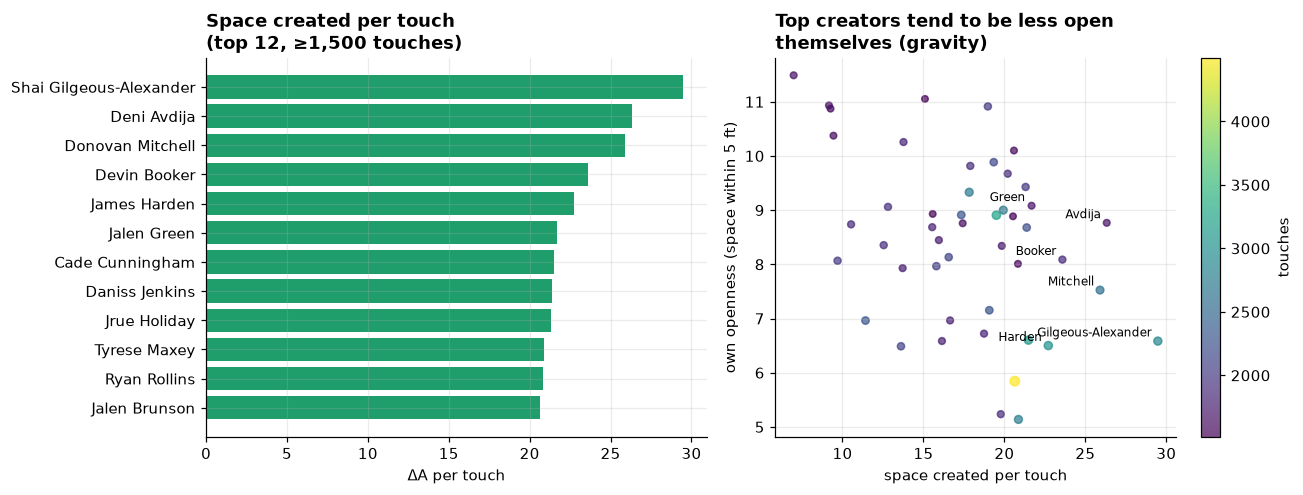

In [8]:
pg = pickle.load(open(R / 'holes/player_game.pkl', 'rb'))
tot = {}
for g, c in pg.items():
    for p, v in c.items():
        t = tot.setdefault(p, {})
        for k, x in v.items(): t[k] = t.get(k, 0) + x
rows = [(p, t['h_create'] / t['h_touches'], t['h_open'] / t['h_off_n'], t['h_touches']) for p, t in tot.items()
        if t.get('h_touches', 0) > 1500 and t.get('h_off_n', 0) > 0]
rows.sort(key=lambda r: -r[1])
fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
top = rows[:12]
ax[0].barh([names.get(p, p) for p, *_ in top][::-1], [r[1] for r in top][::-1], color=C['good'])
ax[0].set_title('Space created per touch\n(top 12, ≥1,500 touches)'); ax[0].set_xlabel('ΔA per touch')
cr = np.array([r[1] for r in rows]); op = np.array([r[2] for r in rows]); tch = np.array([r[3] for r in rows])
sc = ax[1].scatter(cr, op, s=8 + tch / 150, c=tch, cmap='viridis', alpha=0.7)
for p, c_, o_, _ in rows[:6]: ax[1].annotate(names.get(p, p).split()[-1], (c_, o_), fontsize=8, ha='right', xytext=(-4, 3), textcoords='offset points')
ax[1].set_xlabel('space created per touch'); ax[1].set_ylabel('own openness (space within 5 ft)')
ax[1].set_title('Top creators tend to be less open\nthemselves (gravity)'); plt.colorbar(sc, ax=ax[1], label='touches')
plt.tight_layout()

## 6. Rebounding and the true value of a miss

Each miss is modelled as:

1. Where the ball lands: a distribution in the frame of the shot direction, by distance, cross-fit by game.
2. Who controls that landing zone: geometric, Voronoi, kinematic and probabilistic (holes-style) control features.

That gives **P(offensive rebound)**, and then

  **value of a miss = P(OREB) · E[points | OREB] − P(DREB) · E[opponent points | DREB]**

This is the second-chance value *plus* the transition cost. It counts every follow-up make, not only putbacks by the
shooter.

**Why:** a 38% three with good rebounding position behind it is a better shot than its make probability suggests. The
probabilistic control field matches the explicit geometry features, and the two together are best. Voronoi is once again
the weakest.

value of a miss: mean -0.387, sd 0.276, range -0.97 to 0.91


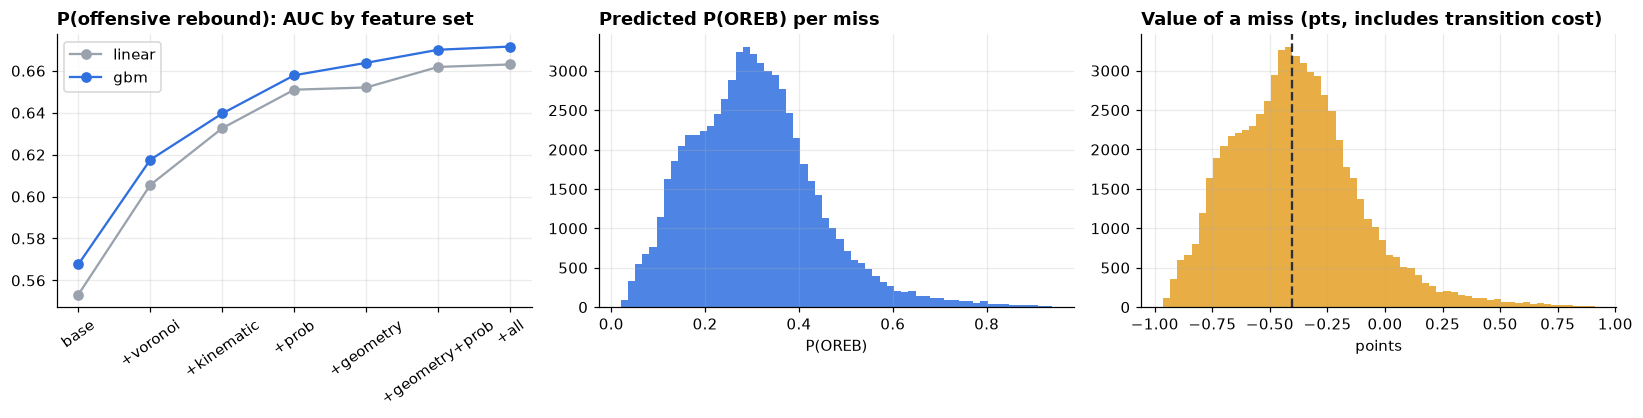

In [9]:
rb = J(R / 'rebounds/rebound_model.json')
arms = ['base', '+voronoi', '+kinematic', '+prob', '+geometry', '+geometry+prob', '+all']
sv = np.load(R / 'rebounds/shots_value.npz')
fig, ax = plt.subplots(1, 3, figsize=(15, 3.9))
for j, (m, c) in enumerate((('linear', C['base']), ('gbm', C['ours']))):
    ax[0].plot(arms, [rb[f'{m}|{a}']['auc'] for a in arms], 'o-', color=c, label=m)
ax[0].set_title('P(offensive rebound): AUC by feature set'); ax[0].legend(); ax[0].tick_params(axis='x', rotation=35)
ax[1].hist(sv['p_oreb'], 60, color=C['ours'], alpha=0.85); ax[1].set_title('Predicted P(OREB) per miss'); ax[1].set_xlabel('P(OREB)')
ax[2].hist(sv['v_miss'], 60, color=C['warn'], alpha=0.85); ax[2].set_title('Value of a miss (pts, includes transition cost)')
ax[2].set_xlabel('points'); ax[2].axvline(np.median(sv['v_miss']), color=C['ink'], ls='--')
plt.tight_layout()
print(f"value of a miss: mean {sv['v_miss'].mean():.3f}, sd {sv['v_miss'].std():.3f}, range {sv['v_miss'].min():.2f} to {sv['v_miss'].max():.2f}")

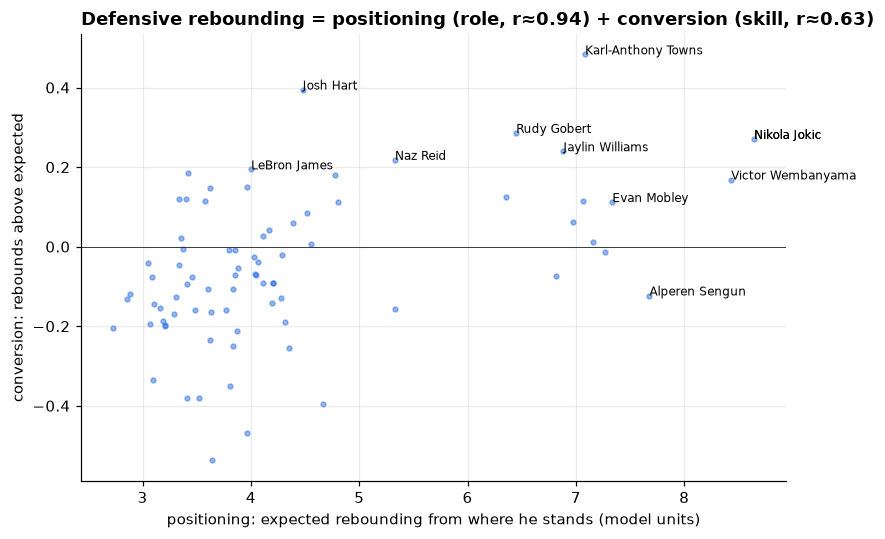

In [10]:
cr = J(R / 'rebounds/player_credit.json')
rows = [(v['name'], v['def']['positioning'], v['def']['conversion'], v['def']['n']) for v in cr.values() if v.get('def', {}).get('n', 0) > 600]
fig, ax = plt.subplots(figsize=(8, 5))
x = np.array([r[1] for r in rows]); y = np.array([r[2] for r in rows])
ax.scatter(x, y, s=10, alpha=0.5, color=C['ours'])
for r in sorted(rows, key=lambda r: -r[2])[:7] + sorted(rows, key=lambda r: -r[1])[:4]:
    ax.annotate(r[0], (r[1], r[2]), fontsize=8)
ax.axhline(0, color=C['ink'], lw=0.6); ax.set_xlabel('positioning: expected rebounding from where he stands (model units)')
ax.set_ylabel('conversion: rebounds above expected')
ax.set_title('Defensive rebounding = positioning (role, r≈0.94) + conversion (skill, r≈0.63)')
plt.tight_layout()

## 7. Holes, rebounding and MAE profiles as rating inputs: none of them help

Each new family of per-player metrics was added to the tracking descriptions feeding the rating prior, and the whole
rolling test was rerun:

* holes: `HOLES=1`
* rebounding: `REB=1`
* MAE player profiles: `MAE=1`, Section 9

**All three made the best model slightly worse.**

**Why:** they are excellent *descriptions*, reliable from one half of the season to the other, but what they mostly
measure is **role**. Where a player stands and what he is asked to do are already captured by box score usage and the
existing tracking metrics. Extra role dimensions add variance to the prior without adding information about *value*.
Only defensive rebound conversion looks like skill, and it is one column out of dozens.

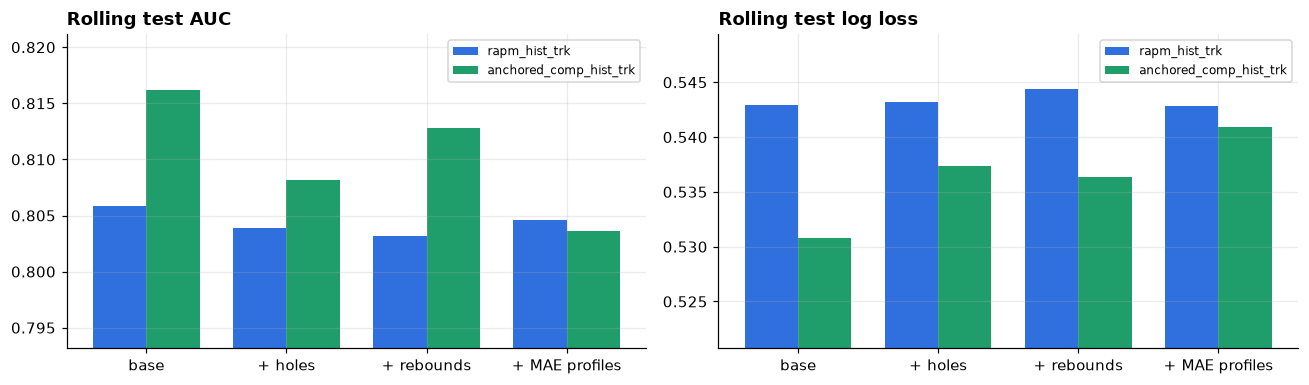

In [11]:
runs = {'base': 'rolling_prior', '+ holes': 'rolling_holes', '+ rebounds': 'rolling_reb', '+ MAE profiles': 'rolling_mae'}
res = {k: J(PC / f'groupwar_t/{v}/rolling_prior.json')['arms'] for k, v in runs.items()}
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for a, met, lab in ((ax[0], 'auc', 'AUC'), (ax[1], 'log_loss', 'log loss')):
    for j, arm in enumerate(['rapm_hist_trk', 'anchored_comp_hist_trk']):
        v = [res[k][arm][met] for k in runs]
        a.bar(np.arange(4) + (j - 0.5) * 0.38, v, 0.38, color=[C['ours'], C['good']][j], label=arm)
    a.set_xticks(range(4), list(runs)); a.set_title(f'Rolling test {lab}'); a.legend(fontsize=8)
    lo_ = min(res[k][arm][met] for k in runs for arm in ['rapm_hist_trk', 'anchored_comp_hist_trk'])
    hi_ = max(res[k][arm][met] for k in runs for arm in ['rapm_hist_trk', 'anchored_comp_hist_trk'])
    a.set_ylim(lo_ - 0.01, hi_ + 0.005)
plt.tight_layout()

## 8. A lineup model that *learns* usage and fit

The goal: don't hard-code "diminishing returns" or "fit". Give the model the *structure* to learn them, and let the data
decide.

* **Usage:** each player has a usage logit u. Within a lineup, his share = softmax(u), fit to who actually used the
  possessions (FGA + 0.44·FTA + TOV).
* **Load cost:** efficiency drops when a player is pushed above his *natural* share
  s₀ = eᵘ/(eᵘ+4), the share he'd take next to four average teammates. The cost is −g·share·(share − s₀), and
  **g is learned**. Lineup changes across a season are the natural experiments that identify it.
* **Fit:** each player has a low-dimensional style vector z. Pairwise terms zᵢᵀWzⱼ, within a team and against the
  opponent, are learned, with their penalty chosen on held-out history.

**What happened:**

1. **On one season (2025-26)** the model can't identify g: it collapses to 0.01–0.13. The fit terms overfit or shrink to zero.
   No gain.
2. **On four seasons (2019-23, 4,443 games)** g is learned consistently, about 0.93–1.15 in every block. The usage arm
   beats additive in **all six** 2022-23 blocks, by +0.007 AUC pooled, but the interval still includes zero. Fit
   is shrunk to about 0 every time.
3. **Moving the learned g back to 2025-26**, and adding that load adjustment to the best model, gives the lowest log
   loss of any arm (0.5259 vs 0.5308). The interval includes zero, and block-level AUC is mixed.

**Reading:** the diminishing-returns effect on usage is real and learnable with enough lineup volume, but it is small.
Pairwise "fit" beyond additive ratings is not detectable at this data size.

4-season additive  AUC 0.649  ll 0.6492  ΔAUC CI [0. 0.]
4-season usage     AUC 0.656  ll 0.6454  ΔAUC CI [-0.003  0.016]
4-season fit       AUC 0.649  ll 0.6492  ΔAUC CI [-0.  0.]
4-season full      AUC 0.657  ll 0.6448  ΔAUC CI [-0.002  0.018]


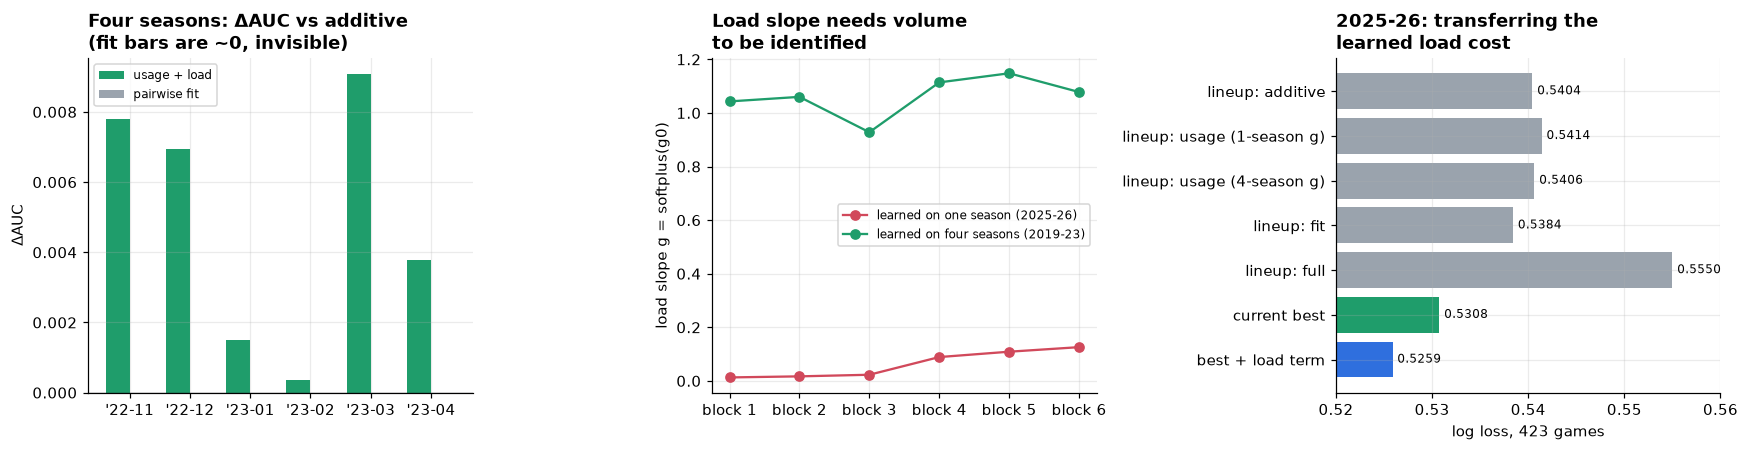

In [12]:
ms = J(PC / 'latent/ms_latent.json')['arms']
blocks = sorted(PC.glob('latent/ms_block_*.npz'))
fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
bl, da, df = [], [], []
for f in blocks:
    b = np.load(f); bl.append(f.stem[-10:-3].replace('2022-', "'22-").replace('2023-', "'23-")); da.append(auc(b['win'], b['usage']) - auc(b['win'], b['additive'])); df.append(auc(b['win'], b['fit']) - auc(b['win'], b['additive']))
x = np.arange(len(bl))
ax[0].bar(x - 0.2, da, 0.4, color=C['good'], label='usage + load'); ax[0].bar(x + 0.2, df, 0.4, color=C['base'], label='pairwise fit')
ax[0].set_xticks(x, bl); ax[0].axhline(0, color=C['ink'], lw=0.8); ax[0].legend(fontsize=8)
ax[0].set_title('Four seasons: ΔAUC vs additive\n(fit bars are ~0, invisible)'); ax[0].set_ylabel('ΔAUC')
# learned slopes from logs/latent.log (1 season) and logs/ms_latent.log (4 seasons), usage arm per block
g1 = [0.013, 0.017, 0.023, 0.089, 0.109, 0.126]; g4 = [1.043, 1.060, 0.928, 1.114, 1.148, 1.078]
ax[1].plot(range(6), g1, 'o-', color=C['bad'], label='learned on one season (2025-26)')
ax[1].plot(range(6), g4, 'o-', color=C['good'], label='learned on four seasons (2019-23)')
ax[1].set_xticks(range(6), [f'block {i + 1}' for i in range(6)]); ax[1].set_ylabel('load slope g = softplus(g0)')
ax[1].set_title('Load slope needs volume\nto be identified'); ax[1].legend(fontsize=8)
lt = J(PC / 'groupwar_t/latent/latent.json')['arms']
arms = ['lat_additive', 'lat_usage', 'lat_usage_ms', 'lat_fit', 'lat_full', 'anchored_comp_hist_trk', 'lat_best_load']
pretty = ['lineup: additive', 'lineup: usage (1-season g)', 'lineup: usage (4-season g)', 'lineup: fit', 'lineup: full',
          'current best', 'best + load term']
y = np.arange(len(arms))[::-1]
ax[2].barh(y, [lt[a]['log_loss'] for a in arms], color=[C['base']] * 5 + [C['good'], C['ours']])
ax[2].set_yticks(y, pretty); ax[2].set_xlim(0.52, 0.56); ax[2].set_xlabel('log loss, 423 games')
for yy, a in zip(y, arms): ax[2].text(lt[a]['log_loss'] + 0.0005, yy, f"{lt[a]['log_loss']:.4f}", va='center', fontsize=8)
ax[2].set_title('2025-26: transferring the\nlearned load cost')
plt.tight_layout()
for k, v in ms.items(): print(f"4-season {k:9s} AUC {v['auc']:.3f}  ll {v['log_loss']:.4f}  ΔAUC CI {np.round(v['d_auc'], 3)}")

## 9. World models: JEPA variants, masked reconstruction and an autoregressive simulator

**Setup.**

* **Data:** 153,557 windows, each 2 s of context and 2 s of future at 5 Hz, from inside one possession.
* **Tokens:** agent × frame, for 5 attackers, 5 defenders and the ball, each as (x, y, vx, vy).
* **Encoder:** a 4-layer transformer.

The variants:

| variant | objective |
|---|---|
| `jepa_time` | predict the *latent* (EMA target encoder) of the future 2 s |
| `jepa_agent` | predict the latents of 1–2 hidden players |
| `jepa_mix` (`_id`) | both masks (plus learned player-identity embeddings) |
| `mae` | same masks, but reconstruct the **raw coordinates** |
| `world` | causal; predict each agent's next-frame move (Gaussian) |
| `random` | untrained encoder (control) |

All JEPAs needed VICReg regularization to avoid collapse.

**Evaluation:** freeze the encoder, then fit *linear* probes on held-out games for shot / open shot / rim attempt in the
next 3 s, shot quality, open space now, and open space 2 s ahead.

**Result.** The latent-prediction JEPAs did *no better than a random network*. They learn coarse "is something about to
happen" signals, and lose the exact geometry the downstream tasks need: their A_now R² falls to 0.16–0.20, against 0.34 for
random. **Masked coordinate reconstruction keeps the geometry and wins.** At this data size, abstraction costs more than
it buys.

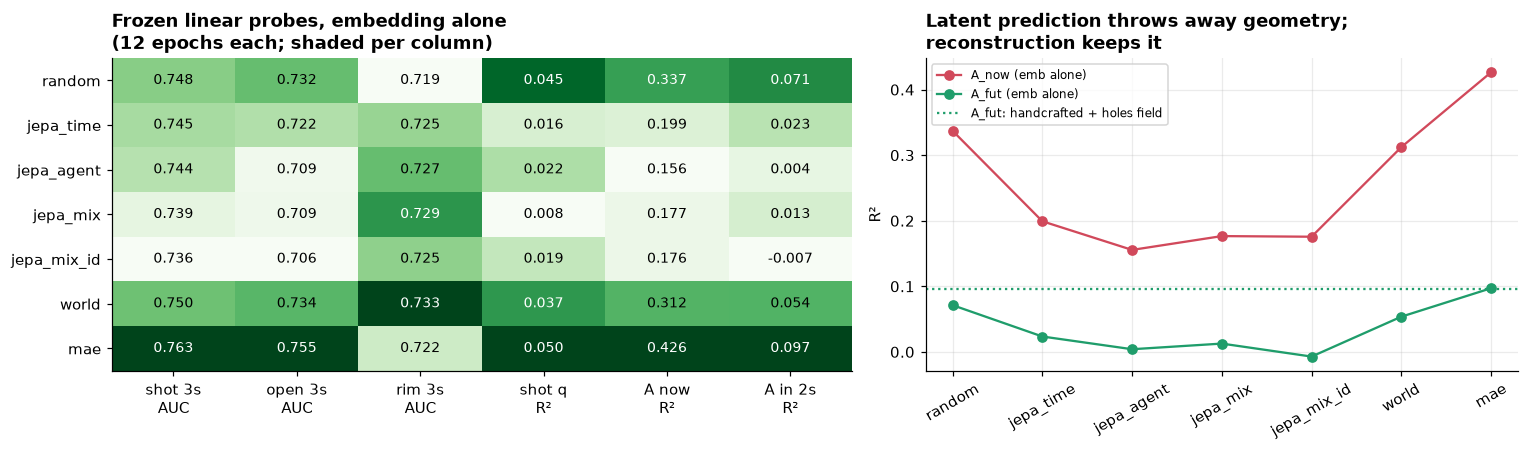

In [13]:
vs = ['random', 'jepa_time', 'jepa_agent', 'jepa_mix', 'jepa_mix_id', 'world', 'mae']
tg = ['shot3', 'open3', 'rim3', 'shot_q', 'A_now', 'A_fut']
P = {v: J(PC / f'jepa/probe_{v}.json') for v in vs}; hc = J(PC / 'jepa/probe_handcrafted.json')
M = np.array([[P[v][f'{t}|emb'] for t in tg] for v in vs])
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw=dict(width_ratios=[1.25, 1]))
Mn = (M - M.min(0)) / (M.max(0) - M.min(0) + 1e-9)
ax[0].imshow(Mn, cmap='Greens', aspect='auto')
for i in range(len(vs)):
    for j in range(len(tg)):
        ax[0].text(j, i, f'{M[i, j]:.3f}', ha='center', va='center', fontsize=9, color='k' if Mn[i, j] < 0.6 else 'w')
ax[0].set_xticks(range(len(tg)), ['shot 3s\nAUC', 'open 3s\nAUC', 'rim 3s\nAUC', 'shot q\nR²', 'A now\nR²', 'A in 2s\nR²'])
ax[0].set_yticks(range(len(vs)), vs); ax[0].grid(False)
ax[0].set_title('Frozen linear probes, embedding alone\n(12 epochs each; shaded per column)')
for t, c in (('A_now', C['bad']), ('A_fut', C['good'])):
    ax[1].plot(vs, [P[v][f'{t}|emb'] for v in vs], 'o-', color=c, label=f'{t} (emb alone)')
ax[1].axhline(hc['A_fut|baseline+field'], color=C['good'], ls=':', label='A_fut: handcrafted + holes field')
ax[1].set_ylabel('R²'); ax[1].legend(fontsize=8); ax[1].tick_params(axis='x', rotation=30)
ax[1].set_title('Latent prediction throws away geometry;\nreconstruction keeps it')
plt.tight_layout()

**Training MAE longer (40 epochs, only on games before 2026-04-01) pays off.** The embedding *alone* now predicts open
space 2 s ahead better than the hand-built geometry plus the full holes field. That is a learned representation
beating our best physics-based feature. Combined with the field, it gets better still.

**Downstream it helped less than the probes suggest:**

* **Shot make:** a small, significant gain on top of the hand-built tracking features (Section 2).
* **Player profiles** (each player's averaged token latent): stable, but again mostly role, so they don't improve the
  rating model (Section 7).

The encoder is a good *scene* model, and the open problem is turning scene understanding into player *value*.

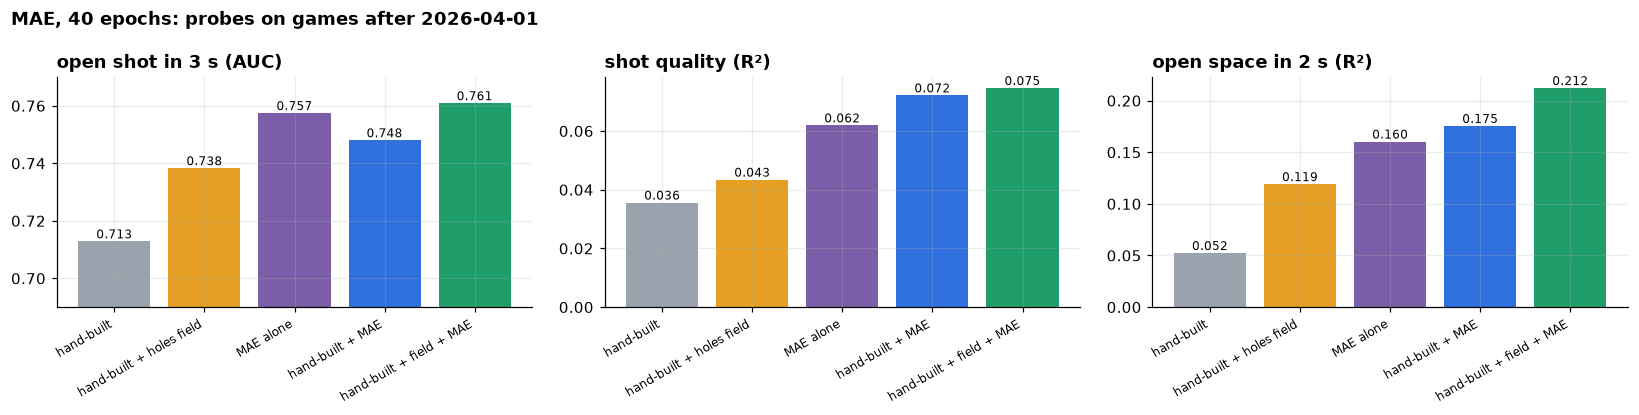

In [14]:
ml = J(PC / 'jepa/probe_mae_long.json')
sets = ['baseline', 'baseline+field', 'emb', 'baseline+emb', 'baseline+field+emb']
pretty = ['hand-built', 'hand-built + holes field', 'MAE alone', 'hand-built + MAE', 'hand-built + field + MAE']
cols = [C['base'], C['warn'], C['alt'], C['ours'], C['good']]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, t, lab in ((ax[0], 'open3', 'open shot in 3 s (AUC)'), (ax[1], 'shot_q', 'shot quality (R²)'), (ax[2], 'A_fut', 'open space in 2 s (R²)')):
    v = [ml[f'{t}|{s}'] for s in sets]
    a.bar(range(5), v, color=cols); a.set_xticks(range(5), pretty, rotation=30, ha='right', fontsize=8); a.set_title(lab)
    for i, x in enumerate(v): a.text(i, x, f'{x:.3f}', ha='center', va='bottom', fontsize=8)
    if t == 'open3': a.set_ylim(0.69, 0.77)
plt.suptitle('MAE, 40 epochs: probes on games after 2026-04-01', x=0.01, ha='left', fontweight='bold')
plt.tight_layout()

## 10. What we've learned

| question | answer | evidence |
|---|---|---|
| Does tracking improve shot-make prediction? | **Yes**, mostly through defender features on twos | −0.010 log loss, CI clear of 0 |
| Can a tracking + history prior beat the public metrics? | **Yes**: beats point-in-time DARKO and EPM; ties leaky end-of-season EPM | −0.010 to −0.053 log loss vs DARKO |
| Does a probabilistic control field beat Voronoi? | **Yes**: Voronoi adds ~0, the field adds +0.01–0.03 AUC | Sections 5 and 6 |
| Do holes, rebounding or MAE profiles improve player ratings? | **No**: reliable, but they describe role | rolling test, Section 7 |
| Can a model *learn* diminishing returns on usage? | **Yes, with volume**: consistent g≈1.1 over four seasons; small gain, not yet significant | Section 8 |
| Can it learn lineup *fit* beyond additive? | **Not detectable** at 4,400 games | Section 8 |
| Which self-supervised objective works on tracking? | **Masked coordinate reconstruction**; latent JEPAs ≈ random | Section 9 |

**Next:**

* Tracking-era multi-season data, to estimate the load cost and fit jointly with tracking descriptions.
* Use the MAE encoder as a *simulator*: counterfactual lineups, roster search.
* Turn space created into value, by linking the field to possession outcomes (EPV) rather than to player descriptions.